# Assignment 1: Data Profiling (EDA) Report
**TTTC3213 Data Engineering** · Dataset: Open University Learning Analytics Dataset (OULAD)

| No. | Name | Matric No. |
|---|---|---|
| 1 | KHEW JUN YU | A216372 |
| 2 | SARAVANA A/L VISVANATHAN | A216453 |
| 3 | ABDUL HADEE BIN JAAPAR | A221505 |

**How to run this notebook**
1. Download OULAD from the official page (link in Section 2) and unzip it.
2. Put the CSV files in `data/oulad/` next to this notebook (`courses.csv`, `assessments.csv`, `studentInfo.csv`, `studentRegistration.csv`, `studentAssessment.csv`, and `studentVle.csv`). The Kaggle copy splits `studentVle.csv` into parts (`studentVle_0.csv` to `studentVle_7.csv`). Put all the parts in the same folder and the notebook joins them automatically.
3. Install the libraries if needed: `pip install pandas numpy matplotlib`
4. Run all cells from top to bottom (Run All). `studentVle.csv` is large (about 10 million rows), so loading it takes about a minute.

The data files are not in this repository because `data/` is in `.gitignore` and `studentVle.csv` is larger than GitHub's 100 MB limit.

## 1. Scenario
The Open University, a large online distance-learning provider, wants to reduce student dropout. We want to find which early signs in students' online activity (clicks on the learning platform) and assessment results can show who is at risk of withdrawing or failing, so tutors can step in sooner.

This data fits the assignment because it is real and messy: it has missing values (deprivation band, registration dates, scores, exam dates), outliers (very high click counts and study credits), inconsistent labels, and sensitive fields such as gender, age, disability and deprivation that create PII and bias risks.

**Questions we want to answer:**
1. Is the data complete and clean enough to compare students who withdrew or failed with students who passed?
2. Which early activity and assessment fields can be trusted, and which need fixing first?
3. Are some student groups too small or too sensitive to use fairly?

## 2. Data source
- **Dataset:** Open University Learning Analytics Dataset (OULAD), released by The Open University (UK) under a CC-BY 4.0 licence.
- **URL:** https://analyse.kmi.open.ac.uk/open_dataset (also mirrored on Kaggle)
- **How we got it:** downloaded the dataset as a zip file and unzipped the CSV files into `data/oulad/`. The large click log `studentVle` comes split into several parts, which the notebook joins back together when loading.
- **Reference:** Kuzilek J., Hlosta M., Zdrahal Z. *Open University Learning Analytics dataset.* Scientific Data 4:170171 (2017).

The dataset covers 7 courses ("modules") run in 2013 and 2014. Presentations starting in February end in **B** and those starting in October end in **J**.

| File | One row means |
|---|---|
| courses | one presentation of a module |
| assessments | one assessment in a module presentation |
| studentInfo | one student in one module presentation (with final result) |
| studentRegistration | one student's registration (and withdrawal date, if any) |
| studentAssessment | one assessment submitted by one student |
| studentVle | clicks by one student on one learning material on one day |

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
DATA = "data/oulad"

needed = ["courses", "assessments", "studentInfo", "studentRegistration", "studentAssessment"]
missing_files = [f for f in needed if not os.path.exists(f"{DATA}/{f}.csv")]
# studentVle can be one file (official download) or split into parts (Kaggle: studentVle_0 ... studentVle_7)
vle_files = sorted(glob.glob(f"{DATA}/studentVle*.csv"))
if not vle_files:
    missing_files.append("studentVle")
print("Missing files:", missing_files if missing_files else "none, all good")
print("studentVle files found:", [os.path.basename(f) for f in vle_files])

Missing files: none, all good
studentVle files found: ['studentVle_0.csv', 'studentVle_1.csv', 'studentVle_2.csv', 'studentVle_3.csv', 'studentVle_4.csv', 'studentVle_5.csv', 'studentVle_6.csv', 'studentVle_7.csv']


In [2]:
def read(path):
    df = pd.read_csv(path, low_memory=False)
    # some copies of the dataset have an extra row-number column ("Unnamed: 0"), we remove it
    return df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]

courses = read(f"{DATA}/courses.csv")
assessments = read(f"{DATA}/assessments.csv")
info = read(f"{DATA}/studentInfo.csv")
reg = read(f"{DATA}/studentRegistration.csv")
sa = read(f"{DATA}/studentAssessment.csv")

# studentVle is very large (about 10 million rows), so we join all its parts
# and use smaller number types to save memory
vle_cols = ["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"]
parts = []
for f in vle_files:
    part = read(f)
    if set(vle_cols).issubset(part.columns):
        part = part[vle_cols]
    else:                                       # a part saved without a header row
        part = pd.read_csv(f, header=None, low_memory=False).iloc[:, -6:]
        part.columns = vle_cols
    parts.append(part)
vle = pd.concat(parts, ignore_index=True)
del parts
vle = vle.astype({"code_module": "category", "code_presentation": "category",
                  "id_student": "int32", "id_site": "int32",
                  "date": "int32", "sum_click": "int32"})

tables = {"courses": courses, "assessments": assessments, "studentInfo": info,
          "studentRegistration": reg, "studentAssessment": sa, "studentVle": vle}
pd.DataFrame({name: df.shape for name, df in tables.items()}, index=["rows", "columns"]).T

,rows,columns
courses,22,3
assessments,206,6
studentInfo,32593,12
studentRegistration,32593,5
studentAssessment,173912,5
studentVle,10655280,6


## 3. Data profiling and issue handling
First we profile every table with one function, so we can see the data type, how many cells are filled, how many are empty and how many different values each column has.

In [3]:
def profile(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "null_pct": (df.isna().mean() * 100).round(2),
        "unique": df.nunique(),
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })

profile(info)

,dtype,non_null,null_pct,unique,example
code_module,str,32593,0.00,7,AAA
code_presentation,str,32593,0.00,4,2013J
id_student,int64,32593,0.00,28785,11391
gender,str,32593,0.00,2,M
region,str,32593,0.00,13,East Anglian Region
highest_education,str,32593,0.00,5,HE Qualification
imd_band,str,31482,3.41,10,90-100%
age_band,str,32593,0.00,3,55<=
num_of_prev_attempts,int64,32593,0.00,7,0
studied_credits,int64,32593,0.00,61,240


In [4]:
profile(reg)

,dtype,non_null,null_pct,unique,example
code_module,str,32593,0.00,7,AAA
code_presentation,str,32593,0.00,4,2013J
id_student,int64,32593,0.00,28785,11391
date_registration,float64,32548,0.14,332,-159.0
date_unregistration,float64,10072,69.10,416,12.0


In [5]:
profile(sa)

,dtype,non_null,null_pct,unique,example
id_assessment,int64,173912,0.0,188,1752.0
id_student,int64,173912,0.0,23369,11391.0
date_submitted,int64,173912,0.0,312,18.0
is_banked,int64,173912,0.0,2,0.0
score,float64,173739,0.1,101,78.0


In [6]:
profile(assessments)

,dtype,non_null,null_pct,unique,example
code_module,str,206,0.00,7,AAA
code_presentation,str,206,0.00,4,2013J
id_assessment,int64,206,0.00,206,1752
assessment_type,str,206,0.00,3,TMA
date,float64,195,5.34,74,19.0
weight,float64,206,0.00,24,10.0


In [7]:
profile(vle)

,dtype,non_null,null_pct,unique,example
code_module,category,10655280,0.0,7,AAA
code_presentation,category,10655280,0.0,4,2013J
id_student,int32,10655280,0.0,26074,28400
id_site,int32,10655280,0.0,6268,546652
date,int32,10655280,0.0,295,-10
sum_click,int32,10655280,0.0,498,4


**What the profile shows:**
- `id_student` is **not unique** in `studentInfo`, because one student can take more than one module. The real key is `code_module + code_presentation + id_student`.
- `imd_band`, `date_registration`, `date_unregistration`, `score` and assessment `date` have missing values (Section 3.1).
- `code_presentation` (e.g. `2013J`) mixes the year and the start month in one text column (Section 3.3).

### 3.1 Missing values

In [8]:
rows = []
for name, df in tables.items():
    for col, n in df.isna().sum().items():
        if n > 0:
            rows.append({"table": name, "column": col, "missing": n,
                         "missing_pct": round(n / len(df) * 100, 2)})
missing = pd.DataFrame(rows).sort_values("missing_pct", ascending=False)
missing

,table,column,missing,missing_pct
3,studentRegistration,date_unregistration,22521,69.10
0,assessments,date,11,5.34
1,studentInfo,imd_band,1111,3.41
2,studentRegistration,date_registration,45,0.14
4,studentAssessment,score,173,0.10


**Chart 1: missing values per column.** This shows which columns have gaps and how big they are.

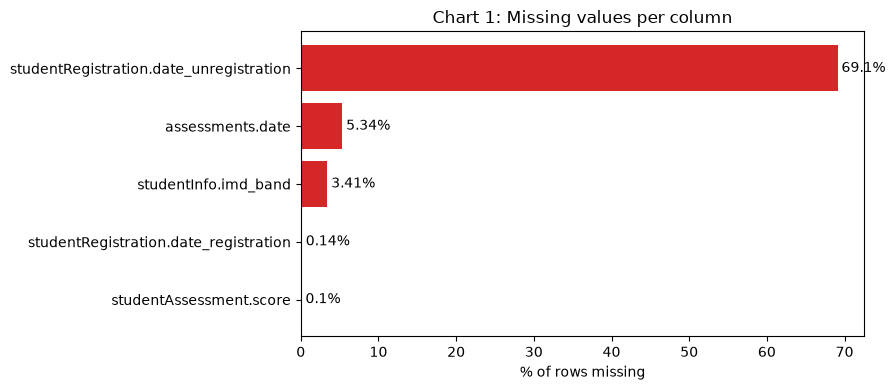

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
labels = missing["table"] + "." + missing["column"]
ax.barh(labels, missing["missing_pct"], color="tab:red")
ax.set_xlabel("% of rows missing")
ax.set_title("Chart 1: Missing values per column")
ax.invert_yaxis()
for i, v in enumerate(missing["missing_pct"]):
    ax.text(v + 0.5, i, f"{v}%", va="center")
plt.tight_layout()
plt.show()

**Chart 2: missing-value heatmap** (registration joined with student info, 2,000 random students). Each dark line is a missing cell. It shows that `date_unregistration` is mostly empty, and the gaps line up with students who did **not** withdraw.

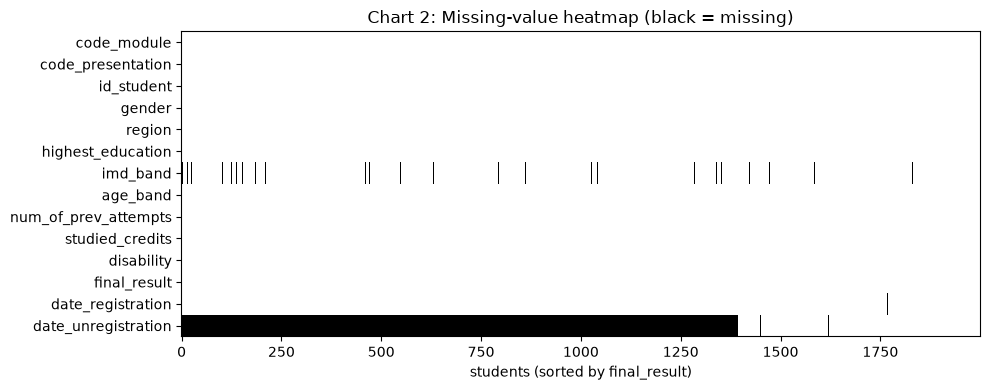

Students with an unregistration date, by final result:
final_result
Distinction    0.000
Fail           0.001
Pass           0.000
Withdrawn      0.991
Name: date_unregistration, dtype: float64


In [10]:
merged = info.merge(reg, on=["code_module", "code_presentation", "id_student"], how="left")
sample = merged.sample(min(2000, len(merged)), random_state=42).sort_values("final_result")
fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(sample.isna().T, aspect="auto", cmap="Greys", interpolation="none")
ax.set_yticks(range(len(sample.columns)))
ax.set_yticklabels(sample.columns)
ax.set_xlabel("students (sorted by final_result)")
ax.set_title("Chart 2: Missing-value heatmap (black = missing)")
plt.tight_layout()
plt.show()

print("Students with an unregistration date, by final result:")
print(merged.groupby("final_result")["date_unregistration"].apply(lambda s: s.notna().mean().round(3)))

**How we handle each missing column, and why:**

| Column | Missing | Decision | Reason |
|---|---|---|---|
| `studentRegistration.date_unregistration` | 22,521 (69.1%) | **Keep as missing, add a flag** `unregistered` | Empty does not mean "data lost". It means the student never withdrew (Chart 2 shows the gaps are almost all Pass, Fail and Distinction students). Filling it with a number would invent fake withdrawal dates. |
| `assessments.date` | 11 (5.3%) | **Fill with the course length** from `courses` | Only final exams are missing a date. The dataset documentation says a missing exam date means the exam is at the end of the presentation, so we can fill it correctly. |
| `studentInfo.imd_band` | 1,111 (3.4%) | **Fill with "Unknown"** | Only a small share is missing. Dropping these students would remove real withdrawals and fails. Guessing a deprivation level would be wrong, and could unfairly label students as poor or rich. |
| `studentRegistration.date_registration` | 45 (0.14%) | **Keep, add a flag** `reg_date_missing` | Very few rows. The rest of the student's data (results, clicks) is still useful, so we don't drop them. |
| `studentAssessment.score` | 173 (0.1%) | **Drop these rows** | Very few rows. We can't know if the student scored 0 or if the score was never recorded, so filling with 0 or the average would give false results. |

In [11]:
reg["unregistered"] = reg["date_unregistration"].notna()
reg["reg_date_missing"] = reg["date_registration"].isna()

info["imd_band"] = info["imd_band"].fillna("Unknown")

assessments = assessments.merge(courses, on=["code_module", "code_presentation"], how="left")
exam_dates_filled = assessments["date"].isna().sum()
assessments["date"] = assessments["date"].fillna(assessments["module_presentation_length"])

before = len(sa)
sa = sa.dropna(subset=["score"])

print("Assessment dates filled:", exam_dates_filled)
print("Score rows dropped:", before - len(sa), f"({(before - len(sa)) / before * 100:.2f}%)")
print("Missing imd_band left:", info["imd_band"].isna().sum())

Assessment dates filled: 11
Score rows dropped: 173 (0.10%)
Missing imd_band left: 0


### 3.2 Outliers
We use the **IQR rule**: a value is an outlier if it is below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. We check study credits, previous attempts, assessment scores and **early clicks** (total clicks in the first 4 weeks, our main early-activity signal).

In [12]:
# early activity = total clicks per student from before the course start until day 27
early = (vle[vle["date"] < 28]
         .groupby(["code_module", "code_presentation", "id_student"], as_index=False, observed=True)["sum_click"]
         .sum()
         .rename(columns={"sum_click": "early_clicks"}))

def iqr_check(s, name):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < low) | (s > high)).sum()
    return {"column": name, "Q1": q1, "Q3": q3, "low_limit": low, "high_limit": high,
            "max": s.max(), "outliers": n_out, "outlier_pct": round(n_out / len(s) * 100, 2)}

pd.DataFrame([
    iqr_check(info["studied_credits"], "studied_credits"),
    iqr_check(info["num_of_prev_attempts"], "num_of_prev_attempts"),
    iqr_check(sa["score"], "score"),
    iqr_check(early["early_clicks"], "early_clicks"),
])

,column,Q1,Q3,low_limit,high_limit,max,outliers,outlier_pct
0,studied_credits,60.0,120.0,-30.0,210.0,655.0,350,1.07
1,num_of_prev_attempts,0.0,0.0,0.0,0.0,6.0,4172,12.80
2,score,65.0,90.0,27.5,127.5,100.0,3813,2.19
3,early_clicks,87.0,452.0,-460.5,999.5,7570.0,1787,6.21


**Chart 3: boxplots for outliers.** Clicks use a log scale because a few students click thousands of times, which would squash everything else.

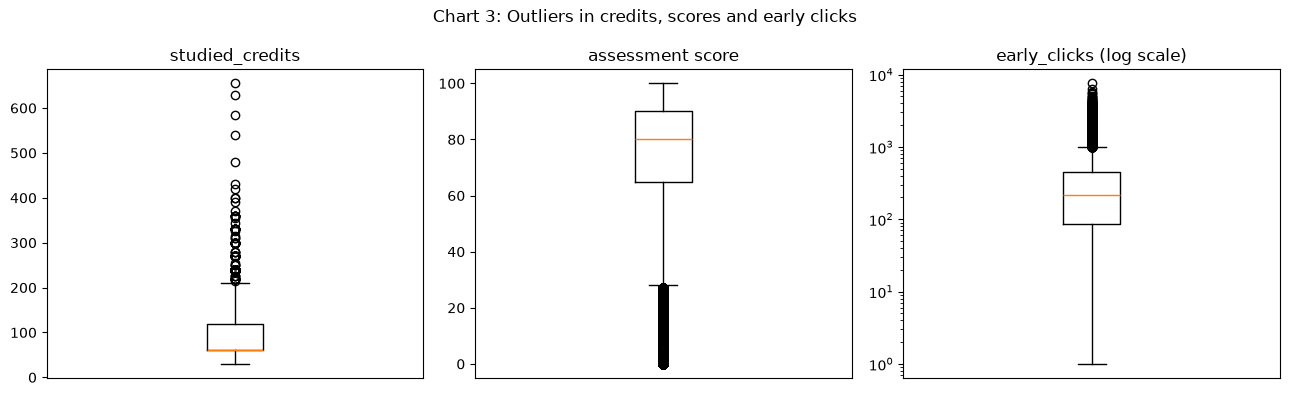

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].boxplot(info["studied_credits"])
axes[0].set_title("studied_credits")
axes[1].boxplot(sa["score"])
axes[1].set_title("assessment score")
axes[2].boxplot(early["early_clicks"])
axes[2].set_yscale("log")
axes[2].set_title("early_clicks (log scale)")
for ax in axes:
    ax.set_xticks([])
fig.suptitle("Chart 3: Outliers in credits, scores and early clicks")
plt.tight_layout()
plt.show()

**What we decided, and why:**

| Column | Outliers (IQR) | Decision | Reason |
|---|---|---|---|
| `early_clicks` | 1,787 (6.2%), above ~1,000 clicks, max 7,570 | **Keep** all values | Very active students are real, not errors. High or low activity is exactly the early sign we want to study, so removing them would delete the signal. We use a log scale when charting instead. |
| `studied_credits` | 350 (1.1%), above 210 credits, max 655 | **Keep, but add a capped copy** at the 99th percentile | Some students really take a heavy load, but a few extreme values (up to 655 credits) would pull averages up. The capped copy keeps every student but limits the effect of extremes. |
| `num_of_prev_attempts` | 4,172 (12.8%), any value above 0 | **Keep** | Most students have 0, so the IQR is 0 and every repeat counts as an "outlier". This shows IQR doesn't suit this column. Repeating a course is a real and useful risk sign. |
| `score` | 3,813 (2.2%), below 27.5 | **Keep** | All scores are within 0–100 (checked in 3.3). Low scores look like outliers, but they are real and important for spotting students at risk. |

In [14]:
cap = info["studied_credits"].quantile(0.99)
info["studied_credits_capped"] = info["studied_credits"].clip(upper=cap)
print("studied_credits capped at", cap, "| rows affected:", (info["studied_credits"] > cap).sum())

studied_credits capped at 240.0 | rows affected: 116


### 3.3 Other quality issues

**a) Duplicates.** We check exact duplicate rows, and duplicate keys (one student should appear only once per module presentation).

In [15]:
key = ["code_module", "code_presentation", "id_student"]
pd.DataFrame({
    "exact_duplicate_rows": {name: df.duplicated().sum() for name, df in tables.items()},
}).assign(duplicate_keys={
    "studentInfo": info.duplicated(subset=key).sum(),
    "studentRegistration": reg.duplicated(subset=key).sum(),
    "studentAssessment": sa.duplicated(subset=["id_assessment", "id_student"]).sum(),
}).fillna("-")

/tmp/ipykernel_10750/3560045516.py:8: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  }).fillna("-")


,exact_duplicate_rows,duplicate_keys
courses,0,-
assessments,0,-
studentInfo,0,0.0
studentRegistration,0,0.0
studentAssessment,0,0.0
studentVle,787170,-


**Result:** `studentInfo`, `studentRegistration` and `studentAssessment` have **no duplicates** (0 exact rows and 0 repeated keys), so each has one row per student. We still run `drop_duplicates` as a safety step, so the notebook stays correct if the data changes.

`studentVle` has **787,170 exact duplicate rows** (same student, material, day and click count). **Fix:** we **combine** them by adding their clicks, so there is one row per student, material and day. We can't tell if a repeated row is double-logging or a second session on the same day, so we keep the activity instead of deleting it. This is a limitation we note in the conclusion.

In [16]:
info = info.drop_duplicates(subset=key)
reg = reg.drop_duplicates(subset=key)
sa = sa.drop_duplicates(subset=["id_assessment", "id_student"])

before = len(vle)
vle = vle.groupby(["code_module", "code_presentation", "id_student", "id_site", "date"],
                  as_index=False, observed=True)["sum_click"].sum()
print("studentVle rows combined:", before - len(vle))
print("studentInfo key still duplicated:", info.duplicated(subset=key).sum())

studentVle rows combined: 2195960
studentInfo key still duplicated: 0


**b) Inconsistent formats.** We check the category labels for odd spellings.

In [17]:
for col in ["imd_band", "age_band", "highest_education", "gender", "disability", "final_result"]:
    print(col, "->", sorted(info[col].astype(str).unique()))

imd_band -> ['0-10%', '10-20', '20-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%', 'Unknown']
age_band -> ['0-35', '35-55', '55<=']
highest_education -> ['A Level or Equivalent', 'HE Qualification', 'Lower Than A Level', 'No Formal quals', 'Post Graduate Qualification']
gender -> ['F', 'M']
disability -> ['N', 'Y']
final_result -> ['Distinction', 'Fail', 'Pass', 'Withdrawn']


**Chart 4: value counts for `imd_band`** before fixing. One band is written as `10-20` without the `%`, so it is counted as a different label from the others.

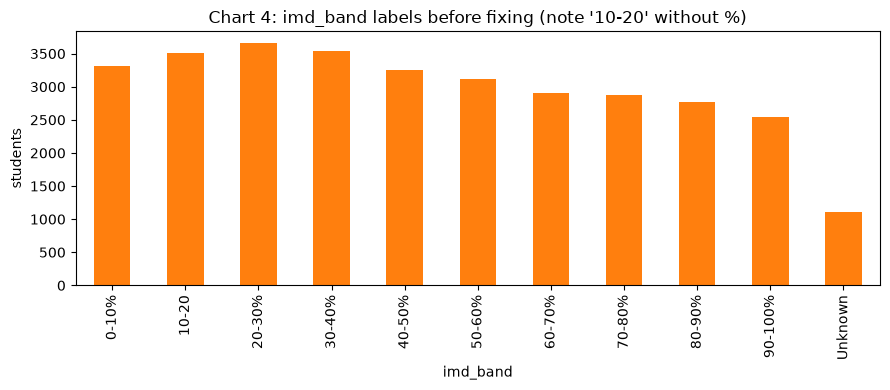

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
info["imd_band"].value_counts().sort_index().plot.bar(ax=ax, color="tab:orange")
ax.set_title("Chart 4: imd_band labels before fixing (note '10-20' without %)")
ax.set_ylabel("students")
plt.tight_layout()
plt.show()

**Fix:** add the missing `%` so every band uses the same format, and rename `55<=` to `55+` so it reads clearly.

In [19]:
info["imd_band"] = info["imd_band"].replace({"10-20": "10-20%"})
info["age_band"] = info["age_band"].replace({"55<=": "55+"})
print(sorted(info["imd_band"].unique()))
print(sorted(info["age_band"].unique()))

['0-10%', '10-20%', '20-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%', 'Unknown']
['0-35', '35-55', '55+']


**c) Wrong data types.** `code_presentation` hides two facts in one text value (`2013J` = year 2013, starts in October). `disability` is stored as `Y`/`N` text. We split and convert them so they can be filtered and grouped properly.

In [20]:
for df in [info, reg, courses, assessments, vle]:
    df["year"] = df["code_presentation"].str[:4].astype(int)
    df["start_month"] = df["code_presentation"].str[-1].map({"B": "February", "J": "October"})

info["disability"] = info["disability"].map({"Y": True, "N": False})
for col in ["code_module", "gender", "region", "highest_education", "imd_band", "age_band", "final_result"]:
    info[col] = info[col].astype("category")

info[["code_presentation", "year", "start_month", "disability"]].head()

,code_presentation,year,start_month,disability
0,2013J,2013,October,False
1,2013J,2013,October,False
2,2013J,2013,October,True
3,2013J,2013,October,False
4,2013J,2013,October,False


**d) Invalid values and logic checks.** Each line asks one question, and the answer is a count. 0 means the check passed.

In [21]:
m = info.merge(reg, on=key, how="left")
checks = {
    "score outside 0-100": (~sa["score"].between(0, 100)).sum(),
    "negative clicks": (vle["sum_click"] < 0).sum(),
    "studied_credits <= 0": (info["studied_credits"] <= 0).sum(),
    "unregistered before registering": (reg["date_unregistration"] < reg["date_registration"]).sum(),
    "Withdrawn but no unregistration date": ((m["final_result"] == "Withdrawn") & m["date_unregistration"].isna()).sum(),
    "has unregistration date but not Withdrawn": ((m["final_result"] != "Withdrawn") & m["date_unregistration"].notna()).sum(),
    "assessment rows with unknown student": (~sa["id_student"].isin(info["id_student"])).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
score outside 0-100,0
negative clicks,0
studied_credits <= 0,0
unregistered before registering,0
Withdrawn but no unregistration date,93
has unregistration date but not Withdrawn,9
assessment rows with unknown student,0


**Result:** scores, clicks, credits and registration dates are all valid (0 problems). But **102 students** have a mismatch: **93** are `Withdrawn` with no unregistration date, and **9** have an unregistration date but are not `Withdrawn`.

**Fix:** we **trust `final_result`** because it is the official course outcome. We add a flag column `needs_check` so these students can be checked or left out of withdrawal-timing analysis. We don't delete them, because their other data is still valid.

**Note:** negative `date` values in `studentVle` and `date_registration` are **not errors**. The dataset counts days from the course start, so negative means before the course began (e.g. registering early or looking at materials in advance).

In [22]:
m["needs_check"] = (
    ((m["final_result"] == "Withdrawn") & m["date_unregistration"].isna()) |
    ((m["final_result"] != "Withdrawn") & m["date_unregistration"].notna()) |
    (m["date_unregistration"] < m["date_registration"])
)
students = m.merge(early, on=key, how="left")
students["early_clicks"] = students["early_clicks"].fillna(0)   # no rows in VLE = no clicks
print("Clean student table:", students.shape)
print("Rows flagged as needs_check:", students["needs_check"].sum())

Clean student table: (32593, 23)
Rows flagged as needs_check: 102


## 4. Exploratory (diagnostic) charts
Charts 1–4 above already expose data problems (missing values, missing-value heatmap, outliers, inconsistent labels). Chart 5 checks **group balance**: whether outcome groups and sensitive groups are big enough to compare fairly.

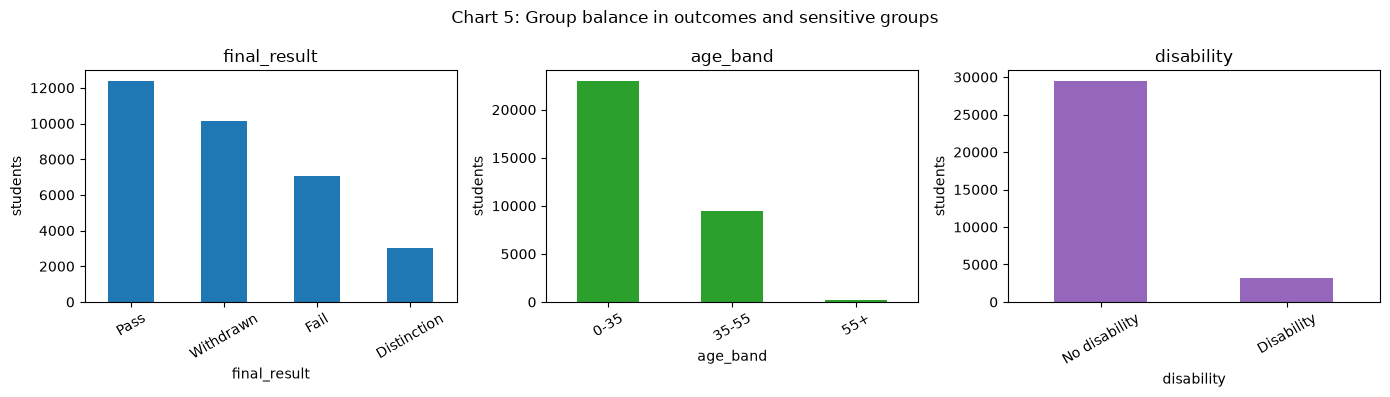

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
students["final_result"].value_counts().plot.bar(ax=axes[0], color="tab:blue", title="final_result")
students["age_band"].value_counts().plot.bar(ax=axes[1], color="tab:green", title="age_band")
students["disability"].map({True: "Disability", False: "No disability"}).value_counts().plot.bar(
    ax=axes[2], color="tab:purple", title="disability")
for ax in axes:
    ax.set_ylabel("students")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Chart 5: Group balance in outcomes and sensitive groups")
plt.tight_layout()
plt.show()

## 5. PII and bias risks
**Personal / sensitive fields:**
- `id_student` is already anonymised (a random number, no names), but combining it with `region`, `age_band`, `gender` and `disability` could still help identify a person in a small group.
- `gender`, `age_band`, `disability` and `imd_band` (deprivation) are **sensitive**. Disability is health-related, and deprivation is linked to income.

**Bias risks:**

In [24]:
risk = students.assign(at_risk=students["final_result"].isin(["Withdrawn", "Fail"]))
for col in ["age_band", "disability", "imd_band", "gender"]:
    t = risk.groupby(col, observed=True)["at_risk"].agg(students="size", at_risk_rate="mean").round(3)
    print(f"\n--- {col} ---")
    print(t)


--- age_band ---
          students  at_risk_rate
age_band                        
0-35         22944         0.550
35-55         9433         0.478
55+            216         0.384

--- disability ---
            students  at_risk_rate
disability                        
False          29429         0.518
True            3164         0.619

--- imd_band ---
          students  at_risk_rate
imd_band                        
0-10%         3311         0.648
10-20%        3516         0.614
20-30%        3654         0.593
30-40%        3539         0.531
40-50%        3256         0.534
50-60%        3124         0.512
60-70%        2905         0.481
70-80%        2879         0.485
80-90%        2762         0.459
90-100%       2536         0.425
Unknown       1111         0.343

--- gender ---
        students  at_risk_rate
gender                        
F          14718         0.516
M          17875         0.538


- **Unbalanced groups:** the `55+` age group has only **216 students** (under 1%), compared with 22,944 in `0-35`. Small groups like this (and `No Formal quals`) give unreliable rates. Disability is also unbalanced: 3,164 students with a disability vs 29,429 without.
- **Unfair targeting:** the at-risk rate (Withdrawn or Fail) is clearly different between groups: **61.9%** for students with a disability vs **51.8%** without, and **64.8%** in the most deprived band (`0-10%`) vs about **48%** in the richer bands. If tutors used `disability`, `imd_band` or `age_band` to predict who is "at risk", students could be labelled just because of who they are, not what they do, and a model could learn and repeat this pattern.
- **Sampling bias:** the data covers only 7 courses from 2013–2014 at one UK university, so results may not apply to other courses, years or countries.

**How we would handle it:**
1. Use **behaviour signals** (early clicks, early scores, late submissions) for alerts, not sensitive fields.
2. Keep sensitive fields only to **check fairness** (e.g. are alerts equally accurate for each group?), with access limited to authorised staff.
3. Don't report results for very small groups, or merge them (e.g. combine small age bands).
4. Remove or generalise fields like `region` if the data is shared outside the university.

## 6. Conclusion
**Is the data fit for the scenario?** Yes, mostly. After fixing the problems above, the data can be used to compare early activity and early assessment results for students who passed with those who withdrew or failed. The key fields (final result, scores, clicks) are mostly complete, and the missing withdrawal dates are explained by design.

**Limitations that remain:**
- 1,111 `imd_band` values (3.4%) are still "Unknown", so deprivation results are incomplete.
- We combined 787,170 repeated click rows, but we can't confirm whether they were double-logged or real repeat sessions.
- 102 students have a `final_result` that disagrees with `date_unregistration`. We flagged them (`needs_check`) instead of guessing.
- Small groups (e.g. only 216 students aged 55+) are too small for reliable conclusions.
- The data is from 2013–2014 and only 7 courses, so patterns may have changed since.